# STATE — Ligand-family training support

Cytokines from the same ligand family may trigger related biological signals. The audit grouped the Parse perturbations by how well their ligand families were represented in training and checked whether greater family support predicted better responses.

Run the six sections in order. Every custom calculation is written in these cells; no external analysis scripts or saved derived tables are required. The analysis uses official STATE released evaluation scores for the HVG and SE representations. The audit does not fine-tune STATE or run fresh inference.

Use Python 3.11 with `numpy==1.26.4 pandas==2.2.2 scipy==1.13.1 matplotlib==3.9.4 pyarrow==16.1.0 rdkit==2025.3.6 ipython ipykernel`. An existing raw-data cache can be selected with `STATE_PRIMARY_INPUTS`; each input is checked against its declared SHA256 before reuse.


## 1. Data source/acquisition

The source table specifies pinned score downloads, split definitions, and annotation inputs. Annotation files are distributed in a versioned public data package; their upstream providers are listed alongside the package URL. Only raw annotations are read from that package.


In [1]:
ANALYSIS_ID="state-featured/test-12"
TITLE='Ligand-family training support'

from pathlib import Path
import ast, csv, gzip, hashlib, io, json, math, os, re, shutil, tarfile, time, tomllib, urllib.request
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
STARTED=time.time()
INPUTS=Path(os.environ.get('STATE_PRIMARY_INPUTS','state_primary_inputs')).resolve()
OUTPUTS=Path('state_primary_outputs')/ANALYSIS_ID.split('/')[-1]
INPUTS.mkdir(parents=True,exist_ok=True)
OUTPUTS.mkdir(parents=True,exist_ok=True)
pd.set_option('display.max_colwidth',100)
pd.set_option('display.max_rows',100)


In [2]:
SOURCES=[{'kind': 'released_score',
  'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'fewshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b',
  'path': 'scores/ST-HVG-Parse/fewshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/fewshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'bytes': 23267,
  'sha256': '09553a37706d948fddf8cf5bacf5b88880cf3cfb90a2b866f08524b49e909401'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'fewshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b',
  'path': 'scores/ST-HVG-Parse/fewshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/fewshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'bytes': 22921,
  'sha256': 'e9d288b06289e24e7928b9a79ccce8ed74a702c9b2fdf92c5a6470aeb11cdbc1'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'fewshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b',
  'path': 'scores/ST-HVG-Parse/fewshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/fewshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'bytes': 20723,
  'sha256': '202ca8338564bcdc2a7c68007b0976800b4dbb7ca5e6d8a0799b0d428615233c'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'fewshot/split_3/eval_best.ckpt/CD4_Memory_results.csv',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b',
  'path': 'scores/ST-HVG-Parse/fewshot/split_3/eval_best.ckpt/CD4_Memory_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/fewshot/split_3/eval_best.ckpt/CD4_Memory_results.csv',
  'bytes': 21260,
  'sha256': '13935da60494fb572039e10aed4f44748bf9e7e8dd0ee2acf4fe8bcfe158a852'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'fewshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b',
  'path': 'scores/ST-HVG-Parse/fewshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/fewshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'bytes': 21542,
  'sha256': '1030abc5a7bd1cb1b9c692c35ba4ce16d0515d299dec9c7cf50eb2ede9641a65'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'zeroshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b',
  'path': 'scores/ST-HVG-Parse/zeroshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/zeroshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'bytes': 33745,
  'sha256': 'f6a553831669d4f5fb0a6957d7f32e815a4fa5be89a0cf13677396b6039aa157'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'zeroshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b',
  'path': 'scores/ST-HVG-Parse/zeroshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/zeroshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'bytes': 32762,
  'sha256': '9a7f4a4c564d25dc2cfe06e25367ae936dc50873aa5711ad26e5d1e3f46d0916'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'zeroshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b',
  'path': 'scores/ST-HVG-Parse/zeroshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/zeroshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'bytes': 27434,
  'sha256': '50b1d9d6f15cbd9d27ccb17e07605f21b94a0e461d346555d81b7d911694d5ec'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'zeroshot/split_3/eval_best.ckpt/CD4_Memory_results.csv',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b',
  'path': 'scores/ST-HVG-Parse/zeroshot/split_3/eval_best.ckpt/CD4_Memory_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/zeroshot/split_3/eval_best.ckpt/CD4_Memory_results.csv',
  'bytes': 31420,
  'sha256': '84f0f00cd17c871b879ee38d92ce5183241c38e1afb20405f3b00e361c98eaa1'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'zeroshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b',
  'path': 'scores/ST-HVG-Parse/zeroshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/zeroshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'bytes': 31512,
  'sha256': 'df68464d3caf07c7c5129a0d911d10ba17c75020e7ac866e4afde28155ac4786'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-SE-Parse',
  'filename': 'fewshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'revision': 'fa458ffda8690c5c5bdff080dfdc46b46713043b',
  'path': 'scores/ST-SE-Parse/fewshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Parse/resolve/fa458ffda8690c5c5bdff080dfdc46b46713043b/fewshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'bytes': 23028,
  'sha256': '06ef8b31481e21845e29eb3408827469eb7da67c01e17c315d2e82d77ddd325a'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-SE-Parse',
  'filename': 'fewshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'revision': 'fa458ffda8690c5c5bdff080dfdc46b46713043b',
  'path': 'scores/ST-SE-Parse/fewshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Parse/resolve/fa458ffda8690c5c5bdff080dfdc46b46713043b/fewshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'bytes': 22494,
  'sha256': '0073fb52db8657ccb14815b58025f53f89abde3a27eb1614c650e930375d3f60'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-SE-Parse',
  'filename': 'fewshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'revision': 'fa458ffda8690c5c5bdff080dfdc46b46713043b',
  'path': 'scores/ST-SE-Parse/fewshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Parse/resolve/fa458ffda8690c5c5bdff080dfdc46b46713043b/fewshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'bytes': 20130,
  'sha256': '87c04e97d215f7bda9a13d602472e62db0be919dc791ab4c4d4732f5a48cf06c'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-SE-Parse',
  'filename': 'fewshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'revision': 'fa458ffda8690c5c5bdff080dfdc46b46713043b',
  'path': 'scores/ST-SE-Parse/fewshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Parse/resolve/fa458ffda8690c5c5bdff080dfdc46b46713043b/fewshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'bytes': 21275,
  'sha256': '3d8466310099d70f91a69725fb0e181e1fd541f57ed644daab5c41be6ae1b88d'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-SE-Parse',
  'filename': 'zeroshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'revision': 'fa458ffda8690c5c5bdff080dfdc46b46713043b',
  'path': 'scores/ST-SE-Parse/zeroshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Parse/resolve/fa458ffda8690c5c5bdff080dfdc46b46713043b/zeroshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'bytes': 33911,
  'sha256': '41377aad49e688a710264d343378e5bc6ce1a698880b8bb1c4f0be9ad025c48f'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-SE-Parse',
  'filename': 'zeroshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'revision': 'fa458ffda8690c5c5bdff080dfdc46b46713043b',
  'path': 'scores/ST-SE-Parse/zeroshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Parse/resolve/fa458ffda8690c5c5bdff080dfdc46b46713043b/zeroshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'bytes': 33789,
  'sha256': 'bb35f1b85f8d9603b10fcf8706602b122bdc520548c9c53f891386dcd40026a1'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-SE-Parse',
  'filename': 'zeroshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'revision': 'fa458ffda8690c5c5bdff080dfdc46b46713043b',
  'path': 'scores/ST-SE-Parse/zeroshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Parse/resolve/fa458ffda8690c5c5bdff080dfdc46b46713043b/zeroshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'bytes': 28814,
  'sha256': '73b37fc58ca8a8734dc5cc34c6b44ec94cdbb6ccb47dadfb3c5bccedf8c99655'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-SE-Parse',
  'filename': 'zeroshot/split_3/eval_best.ckpt/CD4_Memory_results.csv',
  'revision': 'fa458ffda8690c5c5bdff080dfdc46b46713043b',
  'path': 'scores/ST-SE-Parse/zeroshot/split_3/eval_best.ckpt/CD4_Memory_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Parse/resolve/fa458ffda8690c5c5bdff080dfdc46b46713043b/zeroshot/split_3/eval_best.ckpt/CD4_Memory_results.csv',
  'bytes': 31883,
  'sha256': '2cbac97ecdeee9ae7333245fc4d06860969d17d38f2fc4ebea8f99e8af5657fa'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-SE-Parse',
  'filename': 'zeroshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'revision': 'fa458ffda8690c5c5bdff080dfdc46b46713043b',
  'path': 'scores/ST-SE-Parse/zeroshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Parse/resolve/fa458ffda8690c5c5bdff080dfdc46b46713043b/zeroshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'bytes': 30873,
  'sha256': '579286dcc83ffaead762b234891442b560b6213d847956d87147389323c7df5b'},
 {'kind': 'split',
  'path': 'splits/parse_tomls/celltype.toml',
  'url': 'https://raw.githubusercontent.com/shreyjain11/SPECTRAagent/a3b7272548095e7f3df2dabe048c953d0b6316dd/reproduction/primary/state/original/state_generalizability_20260602_single_controller/external/state/state_preprint_toml_files/parse_tomls/celltype.toml',
  'bytes': 2487,
  'sha256': '5f1e7836492e6f39a37fffad93f7dfd78b4cfbd9a9ebb2f63558b39f7a1716cc'},
 {'kind': 'split',
  'path': 'splits/parse_tomls/donor.toml',
  'url': 'https://raw.githubusercontent.com/shreyjain11/SPECTRAagent/a3b7272548095e7f3df2dabe048c953d0b6316dd/reproduction/primary/state/original/state_generalizability_20260602_single_controller/external/state/state_preprint_toml_files/parse_tomls/donor.toml',
  'bytes': 3156,
  'sha256': 'f334a2ab6d01dc89e5c1d7868d8d19990ee1475d50331d30ed2d5148f7cec6cc'},
 {'kind': 'split',
  'path': 'splits/parse_tomls/split_1.toml',
  'url': 'https://raw.githubusercontent.com/shreyjain11/SPECTRAagent/a3b7272548095e7f3df2dabe048c953d0b6316dd/reproduction/primary/state/original/state_generalizability_20260602_single_controller/external/state/state_preprint_toml_files/parse_tomls/split_1.toml',
  'bytes': 1103,
  'sha256': 'c48c807449bfff1bbb8c0070766a9b29198b9b256b14a0f55fba6422a13c420a'},
 {'kind': 'split',
  'path': 'splits/parse_tomls/split_2.toml',
  'url': 'https://raw.githubusercontent.com/shreyjain11/SPECTRAagent/a3b7272548095e7f3df2dabe048c953d0b6316dd/reproduction/primary/state/original/state_generalizability_20260602_single_controller/external/state/state_preprint_toml_files/parse_tomls/split_2.toml',
  'bytes': 1089,
  'sha256': 'ac6847b9eb80098fdbb3f951562dce022cc78d18ea1e07a4ae8157bbbe62d84f'},
 {'kind': 'split',
  'path': 'splits/parse_tomls/split_3.toml',
  'url': 'https://raw.githubusercontent.com/shreyjain11/SPECTRAagent/a3b7272548095e7f3df2dabe048c953d0b6316dd/reproduction/primary/state/original/state_generalizability_20260602_single_controller/external/state/state_preprint_toml_files/parse_tomls/split_3.toml',
  'bytes': 1093,
  'sha256': 'e4fc3ff1e036f8ec9e3b16418f7bfad569a72fee35dcc101fc13bfd77fef5f87'},
 {'kind': 'split',
  'path': 'splits/parse_tomls/split_4.toml',
  'url': 'https://raw.githubusercontent.com/shreyjain11/SPECTRAagent/a3b7272548095e7f3df2dabe048c953d0b6316dd/reproduction/primary/state/original/state_generalizability_20260602_single_controller/external/state/state_preprint_toml_files/parse_tomls/split_4.toml',
  'bytes': 1092,
  'sha256': 'd928a7b0086512b15b99d86f551556b15751512ae9d0e3c0f2ff02b52db660e4'},
 {'kind': 'split',
  'path': 'splits/parse_tomls/split_5.toml',
  'url': 'https://raw.githubusercontent.com/shreyjain11/SPECTRAagent/a3b7272548095e7f3df2dabe048c953d0b6316dd/reproduction/primary/state/original/state_generalizability_20260602_single_controller/external/state/state_preprint_toml_files/parse_tomls/split_5.toml',
  'bytes': 1091,
  'sha256': '73f3bacd8446025a17de3ea2cb11b1b2f6762ff8f9b867f6820d40a40ffeb7c6'}]
ANNOTATIONS=[]
ANNOTATION_PACKAGE={'path': 'annotations.tar.gz', 'url': 'https://raw.githubusercontent.com/shreyjain11/SPECTRAagent/a3b7272548095e7f3df2dabe048c953d0b6316dd/reproduction/primary/state/payloads/state-historical-annotations.tar.gz', 'bytes': 40411527, 'sha256': 'ddba844c5803aeb2e32c51f72889b16fc77efa13f1ace9ba541508f4ed31c059'}


In [3]:
def sha256_file(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda:f.read(8<<20),b''):h.update(block)
    return h.hexdigest()

def verified(path,entry):
    return path.is_file() and path.stat().st_size==entry['bytes'] and sha256_file(path)==entry['sha256']

def download(entry):
    path=INPUTS/entry['path']
    if verified(path,entry):return path
    path.parent.mkdir(parents=True,exist_ok=True)
    temporary=path.with_name(path.name+'.part')
    for attempt in range(4):
        try:
            request=urllib.request.Request(entry['url'],headers={'User-Agent':'SPECTRA-notebook/1.0'})
            with urllib.request.urlopen(request,timeout=120) as response, temporary.open('wb') as f:
                shutil.copyfileobj(response,f,8<<20)
            if not verified(temporary,entry):raise ValueError('Download checksum mismatch: '+entry['path'])
            temporary.replace(path)
            return path
        except Exception:
            if attempt==3:raise
            time.sleep(2**attempt)

with ThreadPoolExecutor(max_workers=4) as pool:
    downloaded=list(pool.map(download,SOURCES))
if ANNOTATIONS:
    missing=[s for s in ANNOTATIONS if not verified(INPUTS/s['path'],s)]
    if missing:
        archive_path=download(ANNOTATION_PACKAGE)
        with tarfile.open(archive_path) as archive:
            for entry in missing:
                path=INPUTS/entry['path'];path.parent.mkdir(parents=True,exist_ok=True)
                with archive.extractfile(entry['member']) as source,path.open('wb') as destination:
                    shutil.copyfileobj(source,destination)
                assert verified(path,entry),entry['path']
    assert all(verified(INPUTS/s['path'],s) for s in ANNOTATIONS)
source_receipts=[{'path':s['path'],'url':s['url'],'bytes':s['bytes'],'sha256':s['sha256']} for s in SOURCES]
source_receipts += [{'path':s['path'],'url':ANNOTATION_PACKAGE['url'],'source_url':s['source_url'],'bytes':s['bytes'],'sha256':s['sha256']} for s in ANNOTATIONS]
display(pd.DataFrame(source_receipts)[['path','bytes','url']])
print('Verified source files:',len(source_receipts))


,path,bytes,url
0,scores/ST-HVG-Parse/fewshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv,23267,https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1...
1,scores/ST-HVG-Parse/fewshot/split_1/eval_best.ckpt/B_Naive_results.csv,22921,https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1...
2,scores/ST-HVG-Parse/fewshot/split_2/eval_best.ckpt/Plasmablast_results.csv,20723,https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1...
3,scores/ST-HVG-Parse/fewshot/split_3/eval_best.ckpt/CD4_Memory_results.csv,21260,https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1...
4,scores/ST-HVG-Parse/fewshot/split_4/eval_best.ckpt/CD14_Mono_results.csv,21542,https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1...
5,scores/ST-HVG-Parse/zeroshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv,33745,https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1...
6,scores/ST-HVG-Parse/zeroshot/split_1/eval_best.ckpt/B_Naive_results.csv,32762,https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1...
7,scores/ST-HVG-Parse/zeroshot/split_2/eval_best.ckpt/Plasmablast_results.csv,27434,https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1...
8,scores/ST-HVG-Parse/zeroshot/split_3/eval_best.ckpt/CD4_Memory_results.csv,31420,https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1...
9,scores/ST-HVG-Parse/zeroshot/split_4/eval_best.ckpt/CD14_Mono_results.csv,31512,https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1...


Verified source files: 26


## 2. Data processing

Parse the released condition identifiers and source filenames, retain the context/protocol/representation labels, and read the prospective annotation or chemical features. Metric values remain the official released scores.


In [4]:
def i_norm_name(x: str) -> str:
    x = str(x).strip().lower()
    x = re.sub('\\s+', ' ', x)
    return x

def i_loose_name(x: str) -> str:
    x = i_norm_name(x)
    x = re.sub('\\([^)]*\\)', '', x)
    x = re.sub('\\b(hydrochloride|hydrate|monohydrate|dihydrate|trihydrate|mesylate|maleate|tosylate|sodium|calcium|potassium|phosphate|sulfate|citrate|acetate|hemihydrate|salt|solvate|tf)\\b', '', x)
    x = re.sub('[^a-z0-9]+', '', x)
    return x

def i_parse_perturbation(value: str):
    """Parse STATE perturbation strings into name/dose/unit when possible."""
    if not isinstance(value, str):
        return (None, np.nan, None)
    s = value.strip()
    try:
        obj = ast.literal_eval(s)
        if isinstance(obj, list) and obj and isinstance(obj[0], tuple):
            tup = obj[0]
            name = str(tup[0]).strip()
            dose = float(tup[1]) if len(tup) > 1 else np.nan
            unit = str(tup[2]) if len(tup) > 2 else None
            return (name, dose, unit)
    except Exception:
        pass
    return (s, np.nan, None)

def i_parse_result_path(repo: str, path: str):
    dataset = 'unknown'
    protocol = 'unknown'
    context = None
    split_id = None
    representation = 'SE' if 'ST-SE' in repo else 'HVG'
    if 'Tahoe' in repo:
        dataset = 'Tahoe-100M'
        protocol = 'zeroshot' if path.startswith('zeroshot/') else 'fewshot'
        context = Path(path).name.replace('_results.csv', '')
    elif 'Replogle' in repo:
        dataset = 'Replogle-Nadig'
        parts = path.split('/')
        protocol = parts[0]
        context = parts[1]
    elif 'Parse' in repo:
        dataset = 'Parse-PBMC'
        parts = path.split('/')
        protocol = parts[0]
        split_id = parts[1]
        context = Path(path).name.replace('_results.csv', '')
    return (dataset, protocol, context, split_id, representation)

frames=[]
for source in SOURCES:
    if source['kind']!='released_score':continue
    frame=pd.read_csv(INPUTS/source['path'])
    dataset,protocol,context,split_id,representation=i_parse_result_path(source['repo'],source['filename'])
    for name,value in [('source_repo',source['repo']),('source_path',source['filename']),('dataset_family',dataset),('protocol',protocol),('context',context),('split_id',split_id),('representation',representation)]:frame[name]=value
    parsed=[i_parse_perturbation(x) for x in frame.perturbation]
    frame['perturbation_name']=[x[0] for x in parsed]
    frame['dose']=[x[1] for x in parsed]
    frame['dose_unit']=[x[2] for x in parsed]
    frame['perturbation_norm']=frame.perturbation_name.map(i_norm_name)
    frame['perturbation_loose']=frame.perturbation_name.map(i_loose_name)
    frames.append(frame)
results=pd.concat(frames,ignore_index=True)
results['row_key']=np.arange(len(results)).astype(str)
for metric in ['overlap_at_N','de_sig_genes_recall','pearson_delta']:
    results[metric]=pd.to_numeric(results[metric],errors='coerce')
display(results.groupby(['protocol','representation','context']).size().rename('released_rows').reset_index())


,protocol,representation,context,released_rows
0,fewshot,HVG,B_Intermediate_Memory,62
1,fewshot,HVG,B_Naive,62
2,fewshot,HVG,CD14_Mono,62
3,fewshot,HVG,CD4_Memory,62
4,fewshot,HVG,Plasmablast,62
5,fewshot,SE,B_Intermediate_Memory,62
6,fewshot,SE,B_Naive,62
7,fewshot,SE,CD14_Mono,62
8,fewshot,SE,Plasmablast,62
9,zeroshot,HVG,B_Intermediate_Memory,90


In [5]:
def b_norm_symbol(x: object) -> str:
    if pd.isna(x):
        return ''
    return re.sub('\\s+', '', str(x).strip()).upper()

def b_norm_ligand(x: object) -> str:
    if pd.isna(x):
        return ''
    s = str(x).strip().lower()
    s = s.replace('_', '-')
    s = re.sub('\\s+', '-', s)
    return s

def b_load_replogle_tomls() -> dict[str, dict[str, set[str]]]:
    out: dict[str, dict[str, set[str]]] = {}
    for path in sorted((b_TOML_ROOT / 'replogle_tomls').glob('*.toml')):
        if path.name.endswith('_zeroshot.toml'):
            continue
        context = path.stem
        data = tomllib.loads(path.read_text())
        few = data.get('fewshot', {})
        key = f'replogle.{context}'
        spec = few.get(key, {})
        test = {b_norm_symbol(x) for x in spec.get('test', []) if b_norm_symbol(x)}
        val = {b_norm_symbol(x) for x in spec.get('val', []) if b_norm_symbol(x)}
        out[context] = {'test': test, 'val': val}
    return out

def b_load_parse_tomls() -> dict[str, dict[str, set[str]]]:
    out: dict[str, dict[str, set[str]]] = {}
    for path in sorted((b_TOML_ROOT / 'parse_tomls').glob('split_*.toml')):
        if path.name.endswith('_zeroshot.toml'):
            continue
        data = tomllib.loads(path.read_text())
        few = data.get('fewshot', {})
        for key, spec in few.items():
            if not key.startswith('parse.'):
                continue
            context = key.split('.', 1)[1]
            test = {b_norm_ligand(x) for x in spec.get('test', []) if b_norm_ligand(x)}
            val = {b_norm_ligand(x) for x in spec.get('val', []) if b_norm_ligand(x)}
            out[context] = {'test': test, 'val': val}
    return out

def b_split_pipe(x: object) -> list[str]:
    if pd.isna(x):
        return []
    text = str(x).strip()
    if not text:
        return []
    parts = re.split('\\|', text)
    return [p.strip() for p in parts if p.strip()]

def b_load_hgnc() -> tuple[dict[str, dict[str, object]], dict[str, str]]:
    path = b_EXT / 'hgnc_complete_set.txt'
    hgnc = pd.read_csv(path, sep='\t', dtype=str, keep_default_na=False)
    symbol_info: dict[str, dict[str, object]] = {}
    alias_to_symbol: dict[str, str] = {}
    for _, row in hgnc.iterrows():
        sym = b_norm_symbol(row.get('symbol'))
        if not sym:
            continue
        groups = b_split_pipe(row.get('gene_group'))
        ensembl = str(row.get('ensembl_gene_id', '')).strip()
        symbol_info[sym] = {'ensembl': ensembl, 'groups': set(groups), 'name': str(row.get('name', '')), 'locus_group': str(row.get('locus_group', ''))}
        alias_to_symbol[sym] = sym
        for field in ['alias_symbol', 'prev_symbol']:
            for alias in b_split_pipe(row.get(field)):
                alias_to_symbol.setdefault(b_norm_symbol(alias), sym)
    return (symbol_info, alias_to_symbol)

def b_load_reactome(symbol_info: dict[str, dict[str, object]], alias: dict[str, str]) -> dict[str, set[str]]:
    ensembl_to_symbol: dict[str, str] = {}
    for sym, info in symbol_info.items():
        ens = str(info.get('ensembl') or '').strip()
        if ens:
            ensembl_to_symbol[ens] = sym
    pathways: dict[str, set[str]] = defaultdict(set)
    path = b_EXT / 'Ensembl2Reactome_Homo_sapiens.txt'
    with path.open() as handle:
        reader = csv.reader(handle, delimiter='\t')
        for row in reader:
            if len(row) < 4:
                continue
            source, pathway, _url, name = row[:4]
            if not source.startswith('ENSG'):
                continue
            sym = ensembl_to_symbol.get(source)
            if not sym:
                continue
            pathways[sym].add(f'{pathway}:{name}')
    return pathways

b_EXT=INPUTS/'annotations'
b_TOML_ROOT=INPUTS/'splits'
b_PRIMARY_METRIC='overlap_at_N'
b_SECONDARY_METRICS=['de_sig_genes_recall','pearson_delta']
results['gene_symbol']=results.perturbation.map(b_norm_symbol)
results['ligand_norm']=results.perturbation.map(b_norm_ligand)


## 3. Axis definition and level construction


Assign cytokine/ligand families by the explicit name rules below. Count members of the same family in the context’s training-reference ligand set. Discovery uses B Intermediate Memory, B Naive and Plasmablast; confirmation uses CD4 Memory and CD14 Mono. Discovery terciles define the support levels.


In [6]:
def b_ligand_family(name: str) -> str:
    s = b_norm_ligand(name)
    if not s:
        return ''
    if s.startswith('il-') or s.startswith('il'):
        m = re.match('il-?(\\d+)', s)
        if m:
            return f'interleukin-{m.group(1)}'
        return 'interleukin'
    if s.startswith('ifn'):
        if 'beta' in s:
            return 'interferon-beta'
        if 'gamma' in s:
            return 'interferon-gamma'
        if 'alpha' in s:
            return 'interferon-alpha'
        if 'lambda' in s:
            return 'interferon-lambda'
        if 'omega' in s:
            return 'interferon-omega'
        return 'interferon'
    if any((k in s for k in ['tnf', 'trail', 'light', 'tl1a', 'tweak', '4-1bbl', 'cd27l', 'cd30l', 'gitr'])):
        return 'tnf-superfamily'
    if any((k in s for k in ['fgf', 'egf', 'hgf', 'vegf', 'igf'])):
        return 'growth-factor'
    if any((k in s for k in ['g-csf', 'gm-csf', 'm-csf', 'flt3l', 'scf'])):
        return 'colony-stem-factor'
    if any((k in s for k in ['c5a', 'leptin', 'osm', 'lif', 'prl', 'epo', 'adfs', 'adsf'])):
        return 'other-cytokine'
    return s.split('-')[0]

def b_infer_parse_train_sets(df: pd.DataFrame, split_specs: dict[str, dict[str, set[str]]]) -> dict[str, set[str]]:
    all_by_context: dict[str, set[str]] = {}
    z = df[(df['dataset_family'] == 'Parse-PBMC') & (df['protocol'] == 'zeroshot')]
    for context, sub in z.groupby('context'):
        all_by_context[str(context)] = {b_norm_ligand(x) for x in sub['perturbation'].dropna() if b_norm_ligand(x)}
    train_by_context = {}
    for context, ligands in all_by_context.items():
        spec = split_specs.get(context, {'test': set(), 'val': set()})
        train_by_context[context] = set(ligands) - set(spec.get('test', set())) - set(spec.get('val', set()))
    return train_by_context

def b_assign_levels_by_cutpoints(values: pd.Series, cutpoints: list[float], labels: list[str]) -> pd.Series:

    def label(v: object) -> str:
        if pd.isna(v):
            return 'unmapped'
        fv = float(v)
        for cp, lab in zip(cutpoints, labels):
            if fv <= cp:
                return lab
        return labels[-1]
    return values.map(label)

df=results
specs = b_load_parse_tomls()
train_by_context = b_infer_parse_train_sets(df, specs)
sub = df[(df['dataset_family'] == 'Parse-PBMC') & (df['protocol'] == 'fewshot')].copy()
sub['ligand_norm'] = sub['perturbation'].map(b_norm_ligand)
sub['ligand_family'] = sub['ligand_norm'].map(b_ligand_family)
rows = []
for idx, row in sub.iterrows():
    ctx = str(row['context'])
    fam = row['ligand_family']
    train = train_by_context.get(ctx, set())
    train_fams = Counter((b_ligand_family(x) for x in train))
    support = train_fams.get(fam, 0)
    rows.append({'row_index': idx, 'parse_train_ligand_count': len(train), 'parse_ligand_family': fam, 'parse_family_train_count': support, 'parse_family_support_fraction': support / len(train) if train else 0.0})
feat = pd.DataFrame(rows).set_index('row_index')
sub = sub.join(feat)
discovery = {'B_Intermediate_Memory', 'B_Naive', 'Plasmablast'}
confirmation = {'CD4_Memory', 'CD14_Mono'}
sub['spectra_subset'] = np.where(sub['context'].isin(discovery), 'discovery_b_cells_plasmablast', 'confirmation_t_mono')
sub = sub[sub['context'].isin(discovery | confirmation)].copy()
q = sub[sub['spectra_subset'] == 'discovery_b_cells_plasmablast']['parse_family_train_count'].quantile([0.33, 0.66]).to_dict()
cps = [float(q[0.33]), float(q[0.66]), float('inf')]
sub['parse_family_support_level'] = b_assign_levels_by_cutpoints(sub['parse_family_train_count'], cps, ['L1_low', 'L2_mid', 'L3_high'])
examples=sub.rename(columns={'ligand_norm':'gene_symbol_canonical'})
FEATURE='parse_family_train_count';LEVEL='parse_family_support_level'
display(cps)


[0.0, 0.0, inf]

## 4. Model results or released scores

Each condition is evaluated using the official `eval_best.ckpt` result file named in section 1. `overlap_at_N` is the primary score; `de_sig_genes_recall` and `pearson_delta` are secondary scores. HVG and SE are kept separate. No audit-specific model fine-tuning is performed.


In [7]:
assert examples.row_key.notna().all()
assert 'overlap_at_N' in examples
score_columns=['source_repo','source_path','context','representation','perturbation','overlap_at_N','de_sig_genes_recall','pearson_delta']
display(examples[score_columns].head(10))
display(examples.groupby(['protocol','representation']).agg(rows=('row_key','size'),valid_overlap=('overlap_at_N','count')))


,source_repo,source_path,context,representation,perturbation,overlap_at_N,de_sig_genes_recall,pearson_delta
0,arcinstitute/ST-HVG-Parse,fewshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv,B_Intermediate_Memory,HVG,4-1BBL,0.207207,0.207207,0.802962
1,arcinstitute/ST-HVG-Parse,fewshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv,B_Intermediate_Memory,HVG,ADSF,0.301887,0.301887,0.772534
2,arcinstitute/ST-HVG-Parse,fewshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv,B_Intermediate_Memory,HVG,BAFF,0.381295,0.381295,0.821668
3,arcinstitute/ST-HVG-Parse,fewshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv,B_Intermediate_Memory,HVG,C5a,0.253012,0.265060,0.835637
4,arcinstitute/ST-HVG-Parse,fewshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv,B_Intermediate_Memory,HVG,CD27L,0.266667,0.341667,0.926905
5,arcinstitute/ST-HVG-Parse,fewshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv,B_Intermediate_Memory,HVG,CD30L,0.327068,0.327068,0.714809
6,arcinstitute/ST-HVG-Parse,fewshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv,B_Intermediate_Memory,HVG,CT-1,0.333333,0.333333,0.947342
7,arcinstitute/ST-HVG-Parse,fewshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv,B_Intermediate_Memory,HVG,EGF,0.268571,0.268571,0.718572
8,arcinstitute/ST-HVG-Parse,fewshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv,B_Intermediate_Memory,HVG,EPO,0.251142,0.251142,0.725556
9,arcinstitute/ST-HVG-Parse,fewshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv,B_Intermediate_Memory,HVG,FGF-beta,0.323077,0.323077,0.831405


rows  valid_overlap
protocol representation                     
fewshot  HVG              310            310
         SE               248            248

## 5. Curves and controls

Calculate per-level means from the individual condition rows. The plots keep each representation and discovery/confirmation subset separate. Controls and contrasts below are calculated from the same rows. Higher overlap@N indicates better prediction.


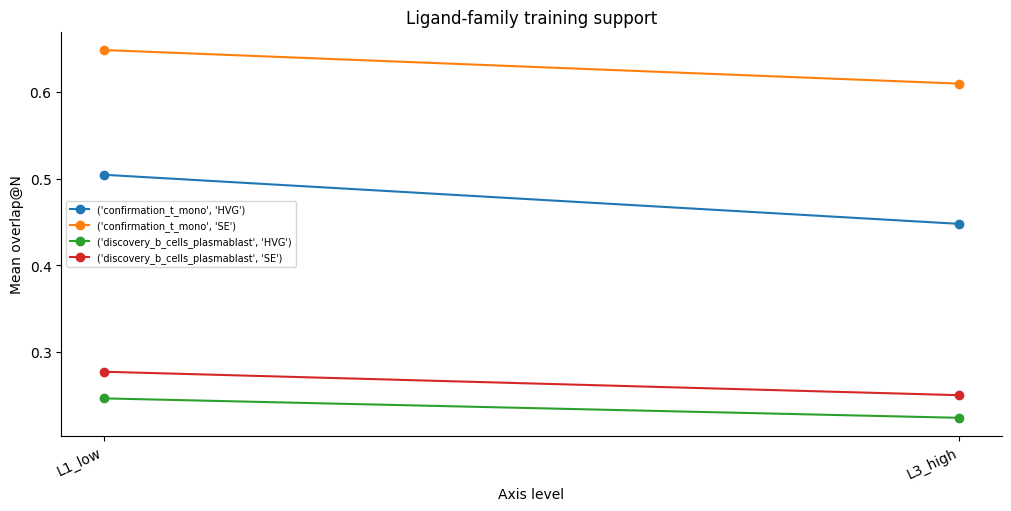

,spectra_subset,representation,level,level_order,n_rows,n_unique_contexts,n_unique_perturbations,similarity_mean,similarity_min,similarity_max,overlap_at_N_mean,overlap_at_N_median,overlap_at_N_std,de_sig_genes_recall_mean,de_sig_genes_recall_median,de_sig_genes_recall_std,pearson_delta_mean,pearson_delta_median,pearson_delta_std
0,confirmation_t_mono,HVG,L1_low,1,90,2,45,0.0,0.0,0.0,0.504313,0.524823,0.172975,0.691503,0.675044,0.093619,0.853997,0.880657,0.100644
1,confirmation_t_mono,HVG,L3_high,3,34,2,17,1.0,1.0,1.0,0.447836,0.495482,0.171431,0.643764,0.635875,0.089590,0.837239,0.867052,0.120964
2,confirmation_t_mono,SE,L1_low,1,45,1,45,0.0,0.0,0.0,0.647887,0.641770,0.087868,0.691674,0.682171,0.087603,0.831736,0.847404,0.083230
3,confirmation_t_mono,SE,L3_high,3,17,1,17,1.0,1.0,1.0,0.609251,0.600282,0.082548,0.645560,0.662937,0.081171,0.807389,0.837798,0.128365
4,discovery_b_cells_plasmablast,HVG,L1_low,1,135,3,45,0.0,0.0,0.0,0.246921,0.268571,0.185468,0.363655,0.382796,0.223682,0.619236,0.753389,0.283232
5,discovery_b_cells_plasmablast,HVG,L3_high,3,51,3,17,1.0,1.0,1.0,0.224560,0.250000,0.171530,0.345935,0.371571,0.205746,0.592215,0.752709,0.301600
6,discovery_b_cells_plasmablast,SE,L1_low,1,135,3,45,0.0,0.0,0.0,0.277602,0.301471,0.202315,0.386612,0.439423,0.249029,0.615353,0.740221,0.288887
7,discovery_b_cells_plasmablast,SE,L3_high,3,51,3,17,1.0,1.0,1.0,0.250604,0.260355,0.177103,0.356466,0.350000,0.203940,0.569191,0.720011,0.309812


,spectra_subset,representation,n_levels,n_rows,similarity_monotone_decreasing_when_order_increases,spearman_level_vs_metric,low_similarity_metric_mean,high_similarity_metric_mean,high_minus_low_metric
0,confirmation_t_mono,HVG,2,124,True,-1.0,0.504313,0.447836,-0.056478
1,confirmation_t_mono,SE,2,62,True,-1.0,0.647887,0.609251,-0.038636
2,discovery_b_cells_plasmablast,HVG,2,186,True,-1.0,0.246921,0.224560,-0.022362
3,discovery_b_cells_plasmablast,SE,2,186,True,-1.0,0.277602,0.250604,-0.026997


In [8]:
def b_safe_mean(values: pd.Series) -> float:
    values = pd.to_numeric(values, errors='coerce').dropna()
    if len(values) == 0:
        return float('nan')
    return float(values.mean())

def b_spearman_monotone(level_df: pd.DataFrame, metric: str) -> float:
    rows = level_df.dropna(subset=['level_order', metric])
    if len(rows) < 2:
        return float('nan')
    return float(rows['level_order'].corr(rows[metric], method='spearman'))

def b_summarize_levels(df: pd.DataFrame, level_col: str, sim_col: str, metrics: list[str]) -> pd.DataFrame:
    level_order = {'L0_no_annotation': 0, 'L1_low': 1, 'L2_mid': 2, 'L3_high': 3, 'L4_very_high': 4, 'no_same_family': 0, 'same_family': 1, 'unmapped': -1}
    rows = []
    for (subset, representation, level), sub in df.groupby(['spectra_subset', 'representation', level_col], dropna=False):
        row = {'spectra_subset': subset, 'representation': representation, 'level': level, 'level_order': level_order.get(str(level), float('nan')), 'n_rows': int(len(sub)), 'n_unique_contexts': int(sub['context'].nunique()), 'n_unique_perturbations': int(sub['gene_symbol_canonical'].nunique() if 'gene_symbol_canonical' in sub else sub['perturbation'].nunique()), 'similarity_mean': b_safe_mean(sub[sim_col]), 'similarity_min': float(pd.to_numeric(sub[sim_col], errors='coerce').min()), 'similarity_max': float(pd.to_numeric(sub[sim_col], errors='coerce').max())}
        for metric in metrics:
            row[f'{metric}_mean'] = b_safe_mean(sub[metric])
            row[f'{metric}_median'] = float(pd.to_numeric(sub[metric], errors='coerce').median())
            row[f'{metric}_std'] = float(pd.to_numeric(sub[metric], errors='coerce').std())
        rows.append(row)
    out = pd.DataFrame(rows)
    return out.sort_values(['spectra_subset', 'representation', 'level_order', 'level']).reset_index(drop=True)

def b_trends_from_levels(levels: pd.DataFrame, metric: str) -> pd.DataFrame:
    rows = []
    for (subset, rep), sub in levels.groupby(['spectra_subset', 'representation']):
        valid = sub[sub['level_order'] >= 0].sort_values('level_order')
        if len(valid) < 2:
            continue
        low = valid.iloc[0]
        high = valid.iloc[-1]
        rows.append({'spectra_subset': subset, 'representation': rep, 'n_levels': int(len(valid)), 'n_rows': int(valid['n_rows'].sum()), 'similarity_monotone_decreasing_when_order_increases': bool(valid['similarity_mean'].is_monotonic_increasing), 'spearman_level_vs_metric': b_spearman_monotone(valid.rename(columns={f'{metric}_mean': metric}), metric), 'low_similarity_metric_mean': float(low[f'{metric}_mean']), 'high_similarity_metric_mean': float(high[f'{metric}_mean']), 'high_minus_low_metric': float(high[f'{metric}_mean'] - low[f'{metric}_mean'])})
    return pd.DataFrame(rows)

def b_bootstrap_gap(df: pd.DataFrame, level_col: str, metric: str, low_levels: set[str], high_levels: set[str], reps: int=2000, seed: int=7) -> dict[str, float]:
    rng = np.random.default_rng(seed)
    data = df[df[level_col].isin(low_levels | high_levels)].copy()
    if data.empty:
        return {'gap_high_minus_low': float('nan'), 'ci_low': float('nan'), 'ci_high': float('nan')}
    low = data[data[level_col].isin(low_levels)][metric].dropna().to_numpy(float)
    high = data[data[level_col].isin(high_levels)][metric].dropna().to_numpy(float)
    if len(low) < 2 or len(high) < 2:
        return {'gap_high_minus_low': float('nan'), 'ci_low': float('nan'), 'ci_high': float('nan')}
    gaps = []
    for _ in range(reps):
        low_s = rng.choice(low, size=len(low), replace=True)
        high_s = rng.choice(high, size=len(high), replace=True)
        gaps.append(float(np.mean(high_s) - np.mean(low_s)))
    return {'gap_high_minus_low': float(np.mean(high) - np.mean(low)), 'ci_low': float(np.quantile(gaps, 0.025)), 'ci_high': float(np.quantile(gaps, 0.975)), 'low_n': int(len(low)), 'high_n': int(len(high))}

curve=b_summarize_levels(examples,LEVEL,FEATURE,['overlap_at_N','de_sig_genes_recall','pearson_delta'])
trends=b_trends_from_levels(curve,'overlap_at_N')

def plot_curve(table,title):
    figure,axis=plt.subplots(figsize=(10,5),layout='constrained')
    group_cols=[x for x in ['spectra_subset','representation'] if x in table]
    order=sorted(table.level.astype(str).unique())
    xmap={value:i for i,value in enumerate(order)}
    groups=table.groupby(group_cols,dropna=False) if group_cols else [('STATE',table)]
    for name,part in groups:
        part=part.copy();part['x']=part.level.astype(str).map(xmap);part=part.sort_values('x')
        axis.plot(part.x,part.overlap_at_N_mean,marker='o',label=str(name))
    axis.set_xticks(range(len(order)),order,rotation=25,ha='right')
    axis.set(xlabel='Axis level',ylabel='Mean overlap@N',title=title)
    axis.legend(fontsize=7);axis.spines[['top','right']].set_visible(False)
    figure.savefig(OUTPUTS/'curve.png',dpi=150)
    plt.show()
plot_curve(curve,TITLE)
display(curve)
display(trends)


In [9]:
context_curves=[]
for context,part in examples.groupby('context'):
    context_curves.append(b_summarize_levels(part.assign(spectra_subset=context),LEVEL,FEATURE,['overlap_at_N']))
context_curve=pd.concat(context_curves,ignore_index=True)
context_trends=b_trends_from_levels(context_curve,'overlap_at_N')
display(context_trends)
context_trends.to_csv(OUTPUTS/'context_trends.csv',index=False)


,spectra_subset,representation,n_levels,n_rows,similarity_monotone_decreasing_when_order_increases,spearman_level_vs_metric,low_similarity_metric_mean,high_similarity_metric_mean,high_minus_low_metric
0,B_Intermediate_Memory,HVG,2,62,True,-1.0,0.348348,0.332361,-0.015987
1,B_Intermediate_Memory,SE,2,62,True,-1.0,0.349192,0.281856,-0.067336
2,B_Naive,HVG,2,62,True,-1.0,0.350235,0.307005,-0.043230
3,B_Naive,SE,2,62,True,-1.0,0.427002,0.381276,-0.045726
4,CD14_Mono,HVG,2,62,True,-1.0,0.607553,0.565539,-0.042014
5,CD14_Mono,SE,2,62,True,-1.0,0.647887,0.609251,-0.038636
6,CD4_Memory,HVG,2,62,True,-1.0,0.401074,0.330132,-0.070942
7,Plasmablast,HVG,2,62,True,-1.0,0.042181,0.034314,-0.007868
8,Plasmablast,SE,2,62,True,1.0,0.056611,0.088681,0.032070


## 6. What the agent decided, and why

The decision below follows the calculated curve and relevant controls. A positive high-minus-low support contrast means better prediction where training-reference support is higher.


In [10]:
confirmation=trends[trends.spectra_subset.str.startswith(('confirmation','zeroshot'))]
supported=len(confirmation)>=2 and (confirmation.high_minus_low_metric>0).all()
decision='Accept support-related degradation on the tested confirmation contexts' if supported else 'Reject consistent support-related degradation on the tested confirmation contexts'
print(decision)
display(confirmation[['spectra_subset','representation','high_minus_low_metric']])
print('Positive contrasts indicate better overlap at higher support; zero or negative contrasts do not support that direction.')


Reject consistent support-related degradation on the tested confirmation contexts


,spectra_subset,representation,high_minus_low_metric
0,confirmation_t_mono,HVG,-0.056478
1,confirmation_t_mono,SE,-0.038636


Positive contrasts indicate better overlap at higher support; zero or negative contrasts do not support that direction.


In [11]:
examples.to_csv(OUTPUTS/'per_condition_results.csv',index=False)
curve.to_csv(OUTPUTS/'curve.csv',index=False)
trends.to_csv(OUTPUTS/'trends.csv',index=False)
receipt={'analysis_id':ANALYSIS_ID,'completed':True,'host':os.uname().nodename,
         'elapsed_seconds':round(time.time()-STARTED,3),'decision':decision,
         'custom_external_code_used':False,'model_inference_performed':False,
         'audit_specific_fine_tuning':False,'source_files':source_receipts,
         'rows':len(examples),'output_files':{name:sha256_file(OUTPUTS/name) for name in
             ['per_condition_results.csv','curve.csv','trends.csv','curve.png']}}
(OUTPUTS/'execution_record.json').write_text(json.dumps(receipt,indent=2,default=str)+'\n')
print('Completed:',ANALYSIS_ID,'on',receipt['host'])


Completed: state-featured/test-12 on exxact05.broadinstitute.org
